# Task: Edge Detection Filters 

**Goal:** apply every filter we covered to **your own picture**, compare the results, and explain what you see.

**Rules**
- Use your own image (a photo with clear objects and some texture works best, not a blank wall).
- Write the code yourself where you see `# TODO`. Hints are given, not solutions.
- Every plot needs a title. Use `plt.figure(figsize=...)` so images are readable.

**Submit:** this notebook with outputs visible + your answers.

**Image note:** No personal photo was attached with this notebook. The setup cell therefore creates a textured demo scene so every section can run. Before submitting as your own-image analysis, set `IMAGE_PATH` to a photo you took and rerun all cells.

## Part 0: Setup & Load Your Image

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-mt8tq81i because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


No personal image was found. Using the generated demo scene.
To use your own photo, set IMAGE_PATH to its file path and rerun the notebook.
Image size (height x width): 480 x 640 pixels


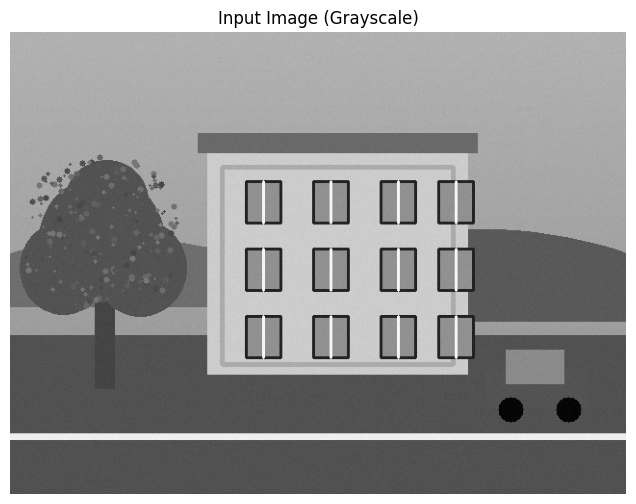

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Replace this with the path to your own photo (JPG or PNG).
IMAGE_PATH = r"your_image_path_here"

def make_demo_image(height=480, width=640):
    """Create a textured demo scene if no personal image path is supplied."""
    rng = np.random.default_rng(7)
    scene = np.zeros((height, width, 3), dtype=np.uint8)

    # Blue sky gradient.
    for y in range(height):
        t = y / max(height - 1, 1)
        scene[y, :, :] = (
            int(220 - 55 * t),  # blue
            int(170 - 25 * t),  # green
            int(105 - 10 * t)   # red
        )

    # Distant hills and ground.
    cv2.ellipse(scene, (115, 285), (190, 70), 0, 180, 360, (75, 125, 75), -1)
    cv2.ellipse(scene, (485, 300), (230, 95), 0, 180, 360, (65, 105, 65), -1)
    cv2.rectangle(scene, (0, 315), (width, height), (75, 85, 80), -1)

    # A building with clear vertical and horizontal edges.
    cv2.rectangle(scene, (205, 115), (475, 355), (170, 175, 180), -1)
    cv2.rectangle(scene, (195, 105), (485, 125), (95, 100, 105), -1)
    cv2.rectangle(scene, (220, 140), (460, 345), (145, 150, 155), 3)
    for x in (245, 315, 385, 445):
        for y in (155, 225, 295):
            cv2.rectangle(scene, (x, y), (x + 36, y + 43), (70, 125, 165), -1)
            cv2.rectangle(scene, (x, y), (x + 36, y + 43), (35, 45, 55), 2)
            cv2.line(scene, (x + 18, y), (x + 18, y + 43), (210, 210, 205), 2)

    # Tree at the left, with branches and textured foliage.
    cv2.rectangle(scene, (88, 245), (108, 370), (55, 65, 95), -1)
    for center, axes in [((95, 215), (65, 65)), ((55, 245), (45, 48)),
                         ((135, 245), (48, 50)), ((100, 175), (43, 42))]:
        cv2.ellipse(scene, center, axes, 0, 0, 360, (45, 105, 55), -1)
    for _ in range(220):
        x = int(rng.integers(15, 175))
        y = int(rng.integers(130, 285))
        if ((x - 95) / 75) ** 2 + ((y - 215) / 80) ** 2 < 1.3:
            shade = int(rng.integers(35, 75))
            cv2.circle(scene, (x, y), int(rng.integers(1, 4)),
                       (shade, shade + 65, shade), -1)

    # A road marking and a small car create additional object boundaries.
    cv2.line(scene, (0, 420), (640, 420), (205, 205, 195), 5)
    cv2.rectangle(scene, (495, 350), (600, 390), (35, 60, 150), -1)
    cv2.rectangle(scene, (515, 330), (575, 365), (55, 115, 175), -1)
    cv2.circle(scene, (520, 392), 13, (25, 25, 25), -1)
    cv2.circle(scene, (580, 392), 13, (25, 25, 25), -1)

    # Subtle fine texture, so the noise experiment is meaningful.
    texture = rng.normal(0, 3, scene.shape).astype(np.int16)
    scene = np.clip(scene.astype(np.int16) + texture, 0, 255).astype(np.uint8)
    return scene

# Load the requested photo in grayscale. If the placeholder path is unchanged
# or the file is missing, use the generated demo scene and explain that choice.
image_file = Path(IMAGE_PATH)
img = cv2.imread(str(image_file), cv2.IMREAD_GRAYSCALE) if IMAGE_PATH != "your_image_path_here" else None

if img is None:
    demo_color = make_demo_image()
    img = cv2.cvtColor(demo_color, cv2.COLOR_BGR2GRAY)
    print("No personal image was found. Using the generated demo scene.")
    print("To use your own photo, set IMAGE_PATH to its file path and rerun the notebook.")
else:
    print(f"Loaded image: {image_file}")

height, width = img.shape
print(f"Image size (height x width): {height} x {width} pixels")

plt.figure(figsize=(8, 6))
plt.imshow(img, cmap="gray")
plt.title("Input Image (Grayscale)")
plt.axis("off")
plt.show()

**Your answer:** The fallback demo image is **480 × 640 pixels** (height × width); the code prints the dimensions of whichever image is loaded. We convert to grayscale because the edge filters measure changes in image intensity. A single intensity channel simplifies the calculations and avoids detecting separate color-channel changes.

## Part 1: Gradients (Sobel)

Compute the horizontal and vertical derivatives, then the magnitude and orientation.

Formulas: `mag = sqrt(gx² + gy²)` and `θ = arctan2(gy, gx)`

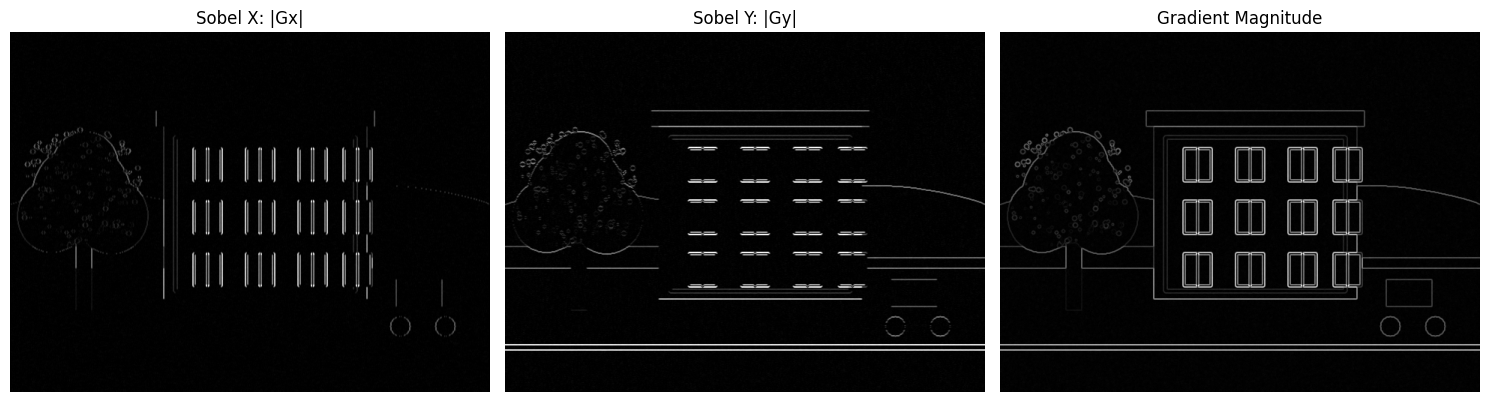

Orientation range: -179.9° to 180.0°


In [2]:
# Sobel derivatives: x detects intensity changes from left to right;
# y detects intensity changes from top to bottom.
grad_x = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
grad_y = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

# Gradient magnitude and orientation (degrees).
magnitude = np.sqrt(grad_x ** 2 + grad_y ** 2)
orientation = np.degrees(np.arctan2(grad_y, grad_x))

# Display absolute derivative responses so negative values are visible too.
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, data, title in zip(
    axes,
    [np.abs(grad_x), np.abs(grad_y), magnitude],
    ["Sobel X: |Gx|", "Sobel Y: |Gy|", "Gradient Magnitude"]
):
    ax.imshow(data, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

print(f"Orientation range: {orientation.min():.1f}° to {orientation.max():.1f}°")

**Your answers:**

- **1a:** The **X gradient** highlights vertical lines. It measures left-to-right intensity changes, which are strong at the left and right borders of vertical objects. In the demo scene, the vertical sides of the building and its window frames are examples.
- **1b:** `cv2.CV_64F` stores signed floating-point results. A derivative can be negative as well as positive. With the default `uint8`, negative values cannot be represented and may be clipped or lost, so the edge response becomes incomplete.

## Part 2: Laplacian

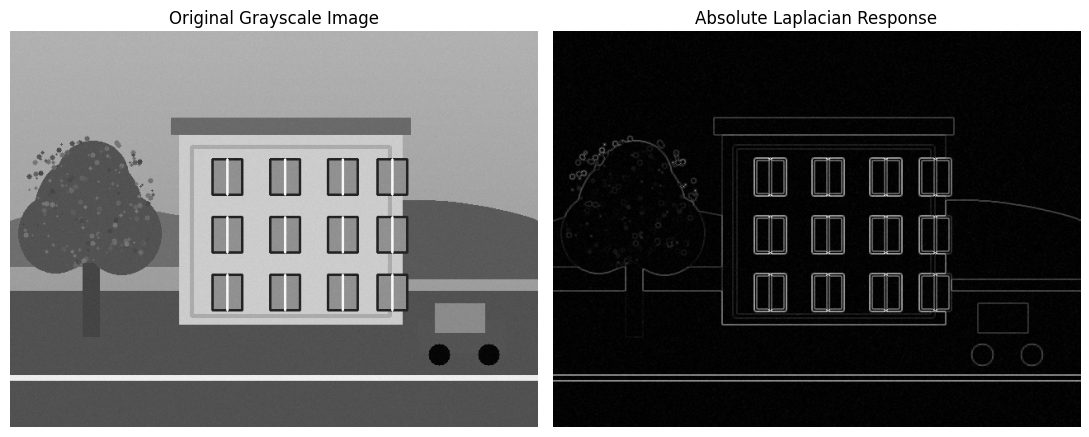

In [3]:
# The Laplacian computes the second spatial derivative.
laplacian = cv2.Laplacian(img, cv2.CV_64F, ksize=3)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Original Grayscale Image")
axes[1].imshow(np.abs(laplacian), cmap="gray")
axes[1].set_title("Absolute Laplacian Response")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Your answer:** Sobel calculates first derivatives in the X and Y directions separately, so it shows the change along each direction and can be combined into a gradient magnitude and orientation. The Laplacian calculates a second derivative and responds to rapid intensity changes in all directions in one result. **The basic Laplacian does not tell us the edge direction**; it gives a direction-independent response and is more sensitive to noise.

## Part 3: Canny

Try **three different threshold pairs** (low, high), for example a low pair, a medium pair, and a high pair.

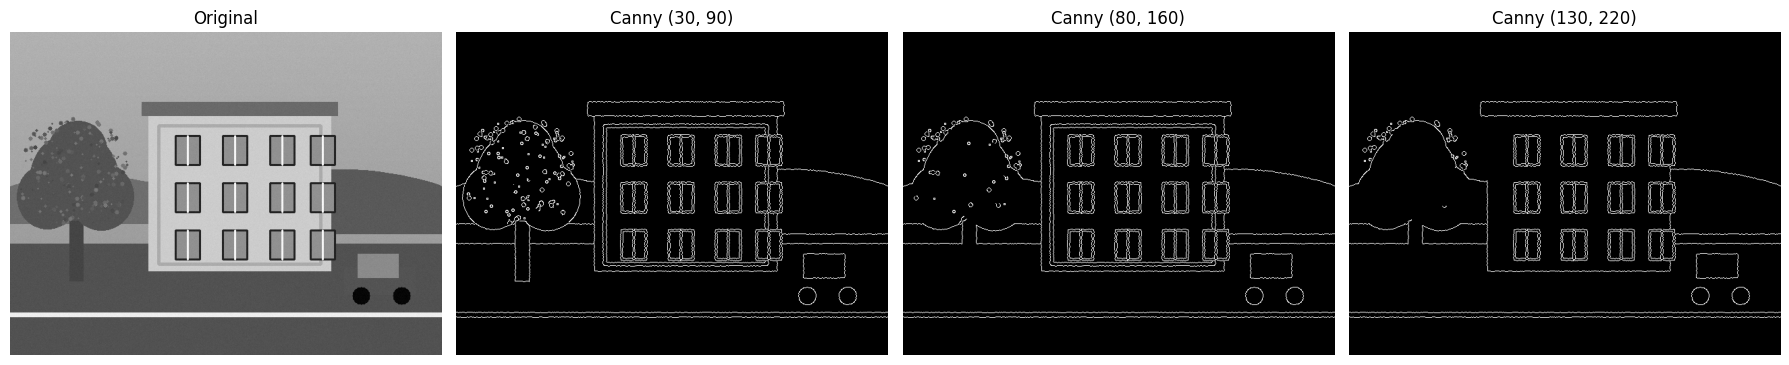

In [4]:
# Increasing both thresholds makes Canny more selective about which edges survive.
threshold_pairs = [(30, 90), (80, 160), (130, 220)]
canny_results = [cv2.Canny(img, low, high) for low, high in threshold_pairs]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
axes[0].imshow(img, cmap="gray")
axes[0].set_title("Original")
axes[0].axis("off")

for ax, result, (low, high) in zip(axes[1:], canny_results, threshold_pairs):
    ax.imshow(result, cmap="gray")
    ax.set_title(f"Canny ({low}, {high})")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Your answers:**

- **3a:** As the low and high thresholds increase, weaker gradient responses are rejected and fewer edges remain. The result becomes less cluttered, but faint edges and some fine details can disappear. Strong object boundaries are more likely to remain.
- **3b:** The five main Canny steps, in order, are:
  1. Gaussian smoothing to reduce noise.
  2. Calculate gradient magnitude and direction.
  3. Non-maximum suppression to thin the edges.
  4. Double thresholding to classify strong, weak, and non-edge pixels.
  5. Edge tracking by hysteresis: keep weak edges connected to strong edges and discard the others.

## Part 4: Roberts & Prewitt (Your Own Kernels)

Define the kernels yourself as NumPy arrays and apply them with `cv2.filter2D`.

- Roberts: 2×2 kernels
- Prewitt: 3×3 kernels (X and Y)

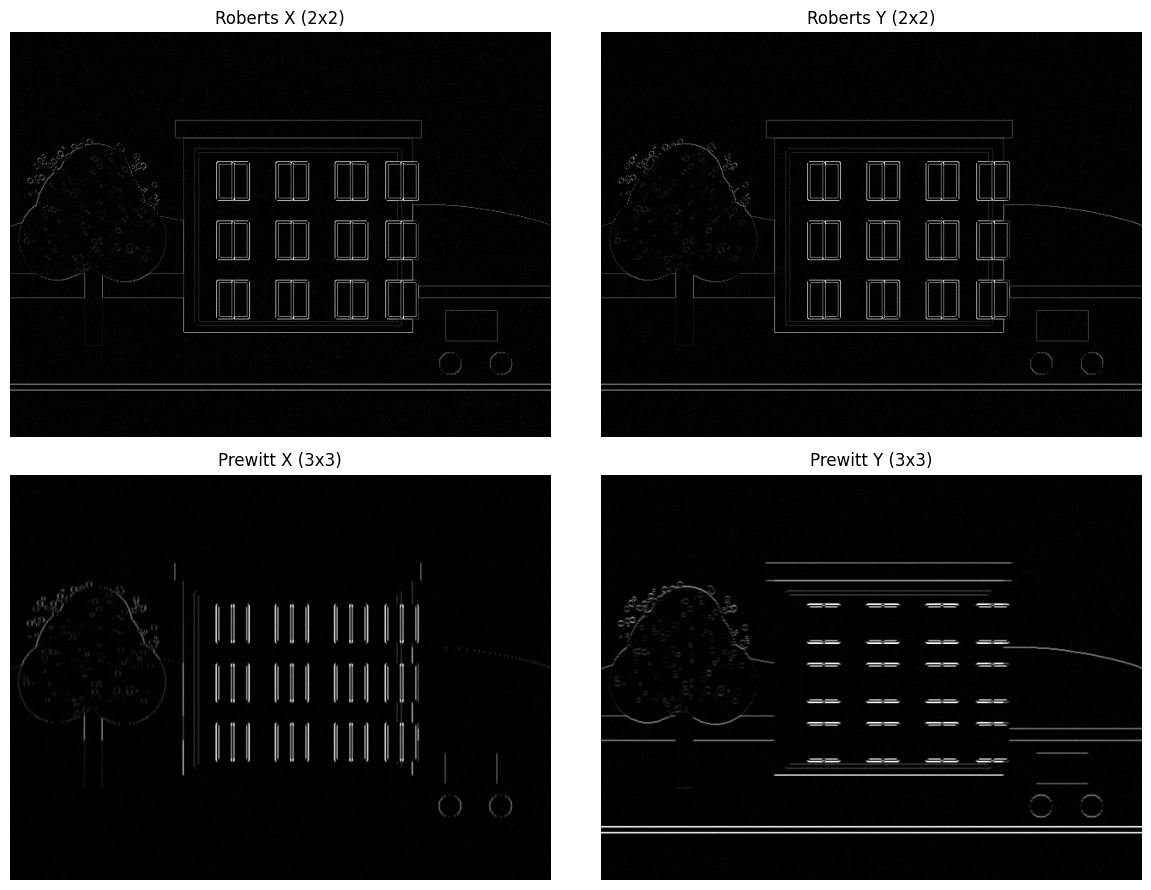

In [5]:
# Define the Roberts (2x2) and Prewitt (3x3) kernels.
roberts_x = np.array([[1, 0],
                      [0, -1]], dtype=np.float32)
roberts_y = np.array([[0, 1],
                      [-1, 0]], dtype=np.float32)

prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]], dtype=np.float32)
prewitt_y = np.array([[-1, -1, -1],
                      [ 0,  0,  0],
                      [ 1,  1,  1]], dtype=np.float32)

# Convert to float32 so filter2D can retain negative derivative responses.
img_float = img.astype(np.float32)
roberts_x_result = cv2.filter2D(img_float, -1, roberts_x)
roberts_y_result = cv2.filter2D(img_float, -1, roberts_y)
prewitt_x_result = cv2.filter2D(img_float, -1, prewitt_x)
prewitt_y_result = cv2.filter2D(img_float, -1, prewitt_y)

results = [
    (np.abs(roberts_x_result), "Roberts X (2x2)"),
    (np.abs(roberts_y_result), "Roberts Y (2x2)"),
    (np.abs(prewitt_x_result), "Prewitt X (3x3)"),
    (np.abs(prewitt_y_result), "Prewitt Y (3x3)")
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (result, title) in zip(axes.ravel(), results):
    ax.imshow(result, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Your answer:** Roberts usually looks noisier on this image. Its **2×2 kernels** use a very small neighborhood and provide little averaging, so small pixel changes and noise can create strong responses. Prewitt uses **3×3 kernels**, which combine information from a larger neighborhood and smooth some variations, although it can still respond to noise.

## Part 5: Sobel 3×3 vs 5×5

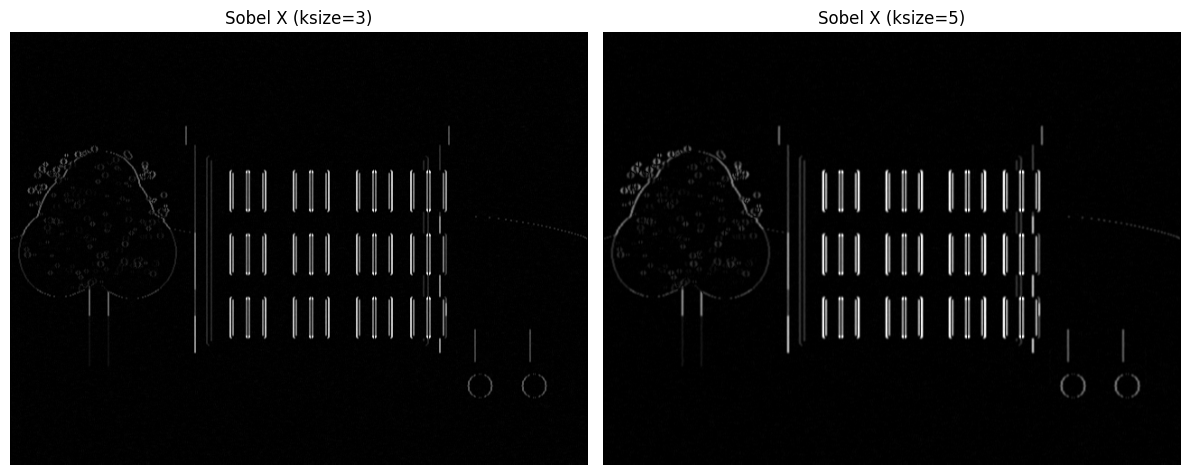

In [6]:
# Compare the horizontal derivative using 3x3 and 5x5 Sobel kernels.
sobel_x_3 = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobel_x_5 = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(np.abs(sobel_x_3), cmap="gray")
axes[0].set_title("Sobel X (ksize=3)")
axes[1].imshow(np.abs(sobel_x_5), cmap="gray")
axes[1].set_title("Sobel X (ksize=5)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Your answer:** The **5×5 Sobel** uses a larger neighborhood, so its response is generally smoother and less affected by tiny local variations. The **3×3 Sobel** tends to preserve finer details and is computationally lighter. I would choose 5×5 when the image is noisy or when I want more stable, broader edge responses; I would choose 3×3 when preserving small details is more important.

## Part 6: Gaussian, LoG & DoG

1. Blur the image with a Gaussian.
2. Apply the Laplacian on the blurred image (**LoG**).
3. Subtract two Gaussian blurs with different sigmas (**DoG**).

Then repeat the DoG with a **second pair of sigmas** (for example `(1, 2)` and `(2, 4)`) and compare.

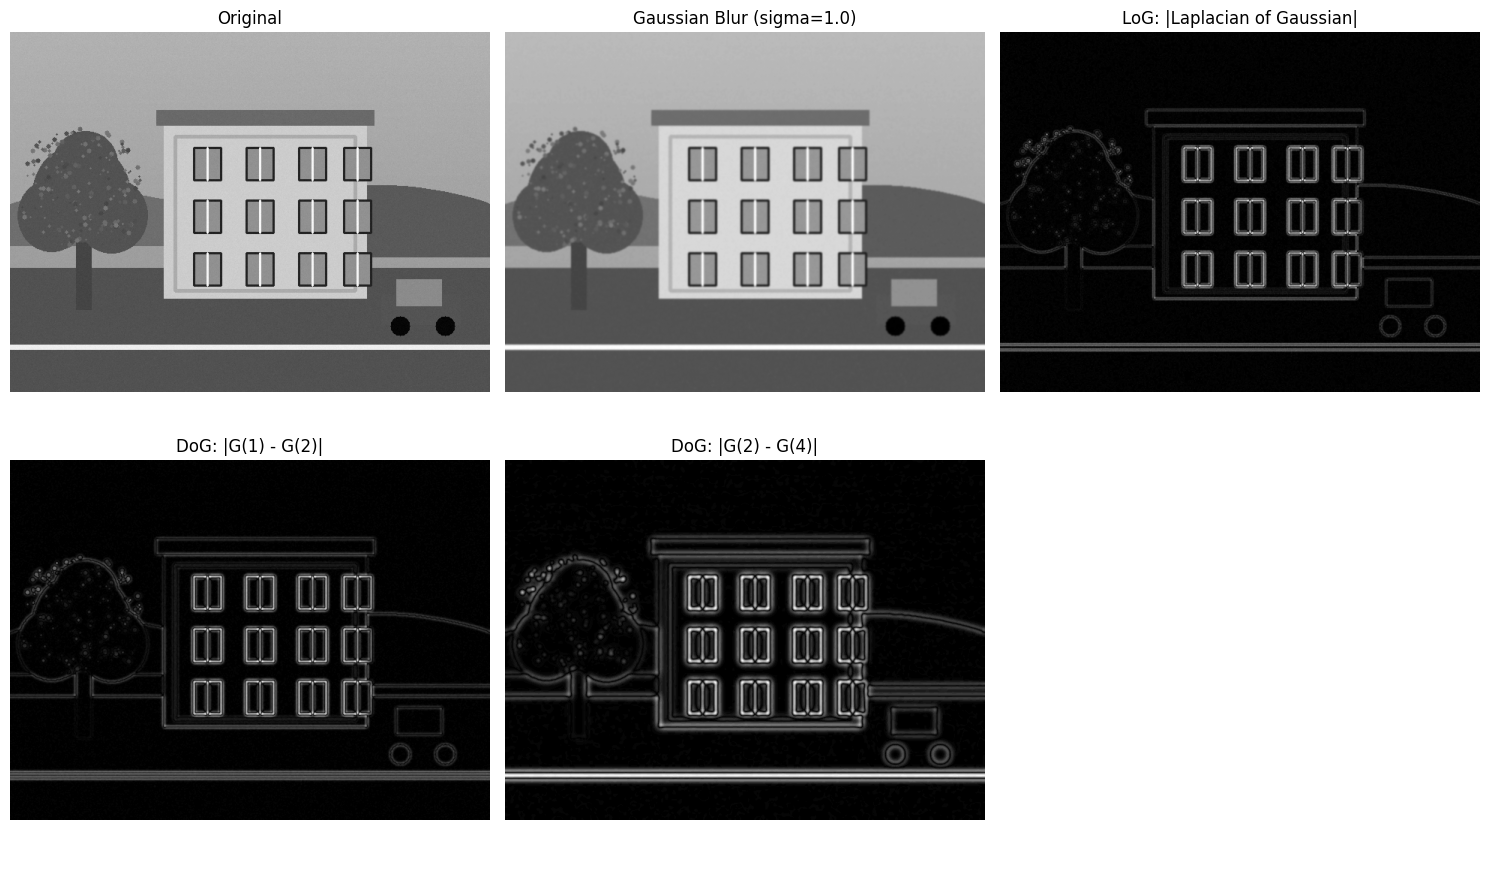

In [7]:
# Gaussian blur and Laplacian of Gaussian (LoG).
sigma_log = 1.0
blurred_log = cv2.GaussianBlur(img, (0, 0), sigmaX=sigma_log)
log_result = cv2.Laplacian(blurred_log, cv2.CV_64F, ksize=3)

# Difference of Gaussians (DoG), repeated with two sigma pairs.
blur_1a = cv2.GaussianBlur(img, (0, 0), sigmaX=1.0)
blur_2a = cv2.GaussianBlur(img, (0, 0), sigmaX=2.0)
dog_1_2 = blur_1a.astype(np.float32) - blur_2a.astype(np.float32)

blur_2b = cv2.GaussianBlur(img, (0, 0), sigmaX=2.0)
blur_4b = cv2.GaussianBlur(img, (0, 0), sigmaX=4.0)
dog_2_4 = blur_2b.astype(np.float32) - blur_4b.astype(np.float32)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
views = [
    (img, "Original"),
    (blurred_log, f"Gaussian Blur (sigma={sigma_log})"),
    (np.abs(log_result), "LoG: |Laplacian of Gaussian|"),
    (np.abs(dog_1_2), "DoG: |G(1) - G(2)|"),
    (np.abs(dog_2_4), "DoG: |G(2) - G(4)|")
]
for ax, (data, title) in zip(axes.ravel(), views):
    ax.imshow(data, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

**Your answers:**

- **6a:** We blur before applying the Laplacian because the Laplacian is a second-derivative filter and strongly amplifies high-frequency noise. Gaussian smoothing reduces that noise and makes the edge response more stable.
- **6b:** Increasing both DoG sigmas makes the blurs broader. The difference therefore emphasizes larger-scale structures and suppresses more fine detail; small features become less prominent. The `(1, 2)` pair retains more fine-scale detail than `(2, 4)`.
- **6c:** **SIFT (Scale-Invariant Feature Transform)** uses Difference of Gaussians to find scale-space extrema for blob/keypoint detection.

## Part 7: Noise Experiment

Add noise to your image and see which filters survive.

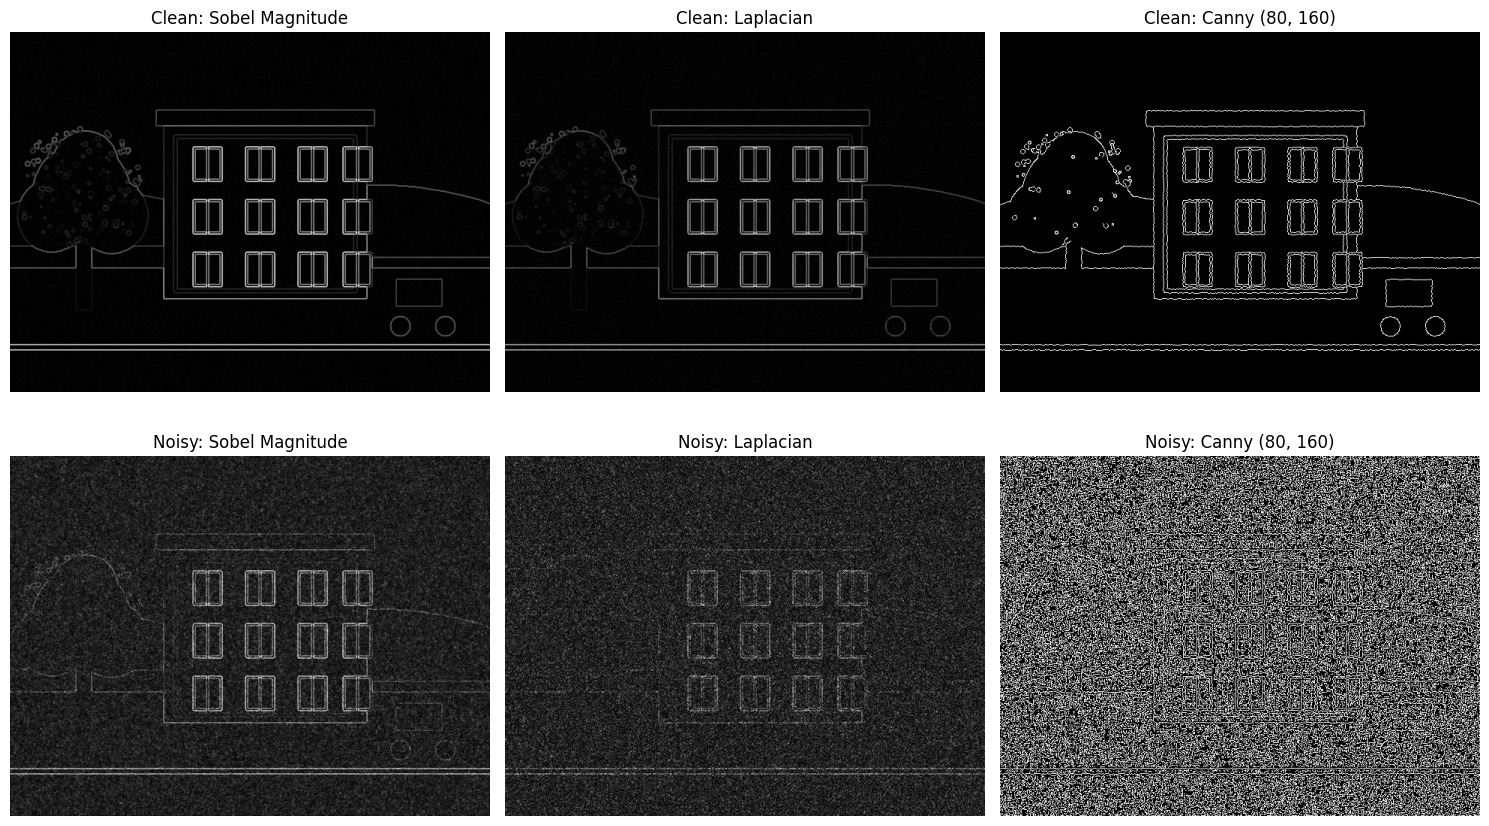

In [8]:
# Add reproducible Gaussian noise (standard deviation = 25).
rng = np.random.default_rng(42)
noise = rng.normal(0, 25, img.shape)
noisy = np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)

# Apply the same three edge methods to clean and noisy versions.
def edge_results(image):
    sx = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)
    sobel_mag = np.sqrt(sx ** 2 + sy ** 2)
    lap = np.abs(cv2.Laplacian(image, cv2.CV_64F, ksize=3))
    canny = cv2.Canny(image, 80, 160)
    return sobel_mag, lap, canny

clean_sobel, clean_lap, clean_canny = edge_results(img)
noisy_sobel, noisy_lap, noisy_canny = edge_results(noisy)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
comparisons = [
    (clean_sobel, "Clean: Sobel Magnitude"),
    (clean_lap, "Clean: Laplacian"),
    (clean_canny, "Clean: Canny (80, 160)"),
    (noisy_sobel, "Noisy: Sobel Magnitude"),
    (noisy_lap, "Noisy: Laplacian"),
    (noisy_canny, "Noisy: Canny (80, 160)")
]
for ax, (data, title) in zip(axes.ravel(), comparisons):
    ax.imshow(data, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Your answer:** In this experiment, the **Laplacian is hurt the most**: its second derivative responds strongly to rapid pixel-to-pixel changes caused by noise, producing many extra responses. **Canny generally handles the noise best** because its pipeline smooths the image with a Gaussian before calculating gradients, then uses non-maximum suppression and thresholding to reduce unwanted edges. Sobel is also affected because derivatives amplify intensity changes, but its first-derivative response is generally less noise-sensitive than the Laplacian.

## Part 8: Final Comparison & Conclusion

Make one summary figure showing: Original, Sobel magnitude, Laplacian, Canny, LoG, DoG.

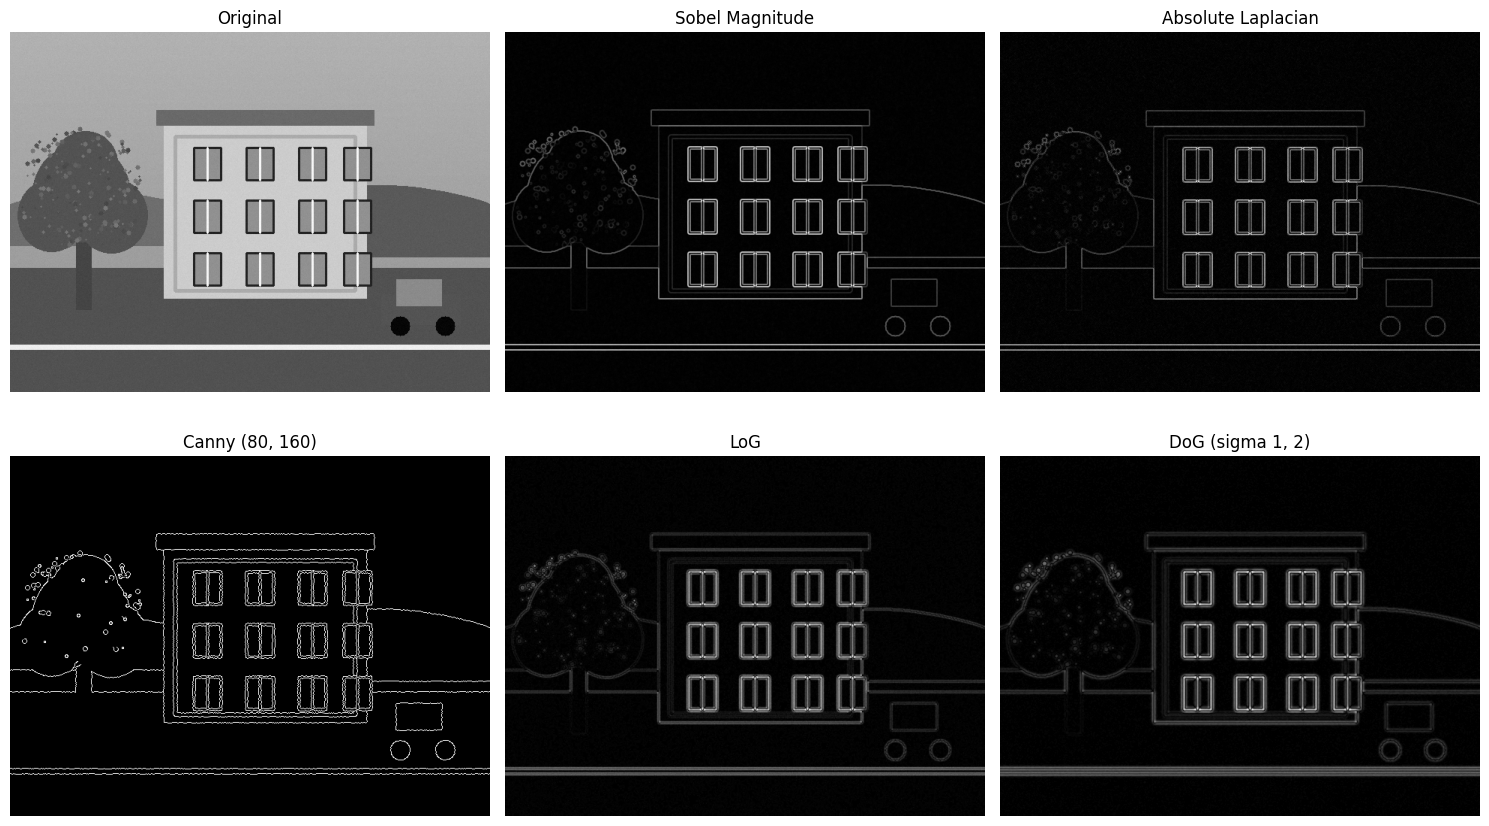

Maximum difference between sqrt-based magnitude and cv2.magnitude: 0.000061


In [9]:
# Final side-by-side comparison of the main methods.
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
final_views = [
    (img, "Original"),
    (magnitude, "Sobel Magnitude"),
    (np.abs(laplacian), "Absolute Laplacian"),
    (canny_results[1], "Canny (80, 160)"),
    (np.abs(log_result), "LoG"),
    (np.abs(dog_1_2), "DoG (sigma 1, 2)")
]
for ax, (data, title) in zip(axes.ravel(), final_views):
    ax.imshow(data, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Bonus check: cv2.magnitude should match the Sobel magnitude calculation.
magnitude_cv = cv2.magnitude(grad_x.astype(np.float32), grad_y.astype(np.float32))
difference = np.max(np.abs(magnitude.astype(np.float32) - magnitude_cv))
print(f"Maximum difference between sqrt-based magnitude and cv2.magnitude: {difference:.6f}")

**Final answer:** For the demo scene, I would choose **Canny** because it produces thin, fairly continuous object boundaries and removes many weak responses. It makes the building, windows, tree, and car easier to distinguish.

There are trade-offs:
1. **Noise:** Canny includes Gaussian smoothing, so it is generally more robust to noise than a direct Laplacian, but smoothing can remove very small details.
2. **Threshold selection:** Its result depends on the low and high thresholds. High values can miss weak edges, while low values can keep unwanted texture.
3. **Processing:** Canny has several stages and is more computationally involved than applying one simple Sobel or Laplacian filter.

**Important:** These observations describe the generated demo scene because no personal photo was attached. Set `IMAGE_PATH` in Part 0 to your own image and run the notebook again before submitting it as an analysis of your own picture.

### Bonus
The code in Part 7 compares the magnitude calculated with `np.sqrt` against `cv2.magnitude`. The printed maximum difference should be very small (floating-point rounding only).